In [1]:
import pandas as pd

In [4]:
df = pd.read_csv('/REDACTED-path/HypoMap3D-data/v0.9/10_analyses/sexual_dimorphism/L4_sd_metrics.csv', index_col='celltype_ID')
df

,n_DEGs,pct_Female,sLISI_pct75
celltype_ID,,,
Gl4-220,561,0.325898,0.981644
Gl4-140,539,0.409053,0.982116
Gb4-438,409,0.333582,0.923493
Gl4-213,400,0.586929,0.991101
Gl4-218,309,0.336940,0.998198
...,...,...,...
Gb4-578,0,0.605322,0.214054
NN4-22,0,0.951456,0.994474
NN4-35,0,0.750000,0.872927


In [13]:
df_sd = df[df['n_DEGs'] >= 100]
sorted_index = sorted(df_sd.index, key=lambda x: int(x.split('-')[-1]))
df_sd.loc[sorted_index]

,n_DEGs,pct_Female,sLISI_pct75
celltype_ID,,,
Gl4-27,209,0.087083,0.992204
Gl4-140,539,0.409053,0.982116
Gl4-213,400,0.586929,0.991101
Gl4-218,309,0.336940,0.998198
Gl4-220,561,0.325898,0.981644
Gl4-221,209,0.299861,0.991093
Gl4-260,183,0.460420,0.984616
Gl4-261,282,0.638992,0.989275
Gl4-264,129,0.356918,0.946020


In [22]:
df_degs = pd.read_csv('/REDACTED-path/HypoMap3D-data/v0.9/10_analyses/sexual_dimorphism/L4_multivariate_sex_edgeR_results_full.csv')
df_degs.columns = ['gene', 'logFC', 'logCPM', 'F', 'PValue', 'FDR', 'id']
df_degs.head(3)

,gene,logFC,logCPM,F,PValue,FDR,id
0,Xist,-9.366312,9.111565,693.382285,1.626745e-23,6.650134e-20,Gl4-293
1,Uty,6.822763,6.542082,398.997189,6.205220e-22,1.268347e-18,Gl4-293
2,Eif2s3y,7.544865,6.604348,321.044229,2.380016e-16,3.243169e-13,Gl4-293


In [23]:
df_degs_sd = df_degs[df_degs['id'].isin(df_sd.index)]
df_degs_sd

,gene,logFC,logCPM,F,PValue,FDR,id
16817,Xist,-11.436805,9.634544,1.209286e+03,5.023546e-26,2.123453e-22,Gb4-664
16818,Ddx3y,4.685350,6.838938,1.593203e+02,1.183884e-17,2.502139e-14,Gb4-664
16819,Socs2,-3.136508,7.182008,1.064327e+02,2.068361e-14,2.914320e-11,Gb4-664
16820,Rgs4,-1.713733,8.000987,7.226344e+01,1.466856e-11,1.550100e-08,Gb4-664
16821,Pde10a,-1.304582,9.229389,5.225276e+01,1.690695e-09,1.201203e-06,Gb4-664
...,...,...,...,...,...,...,...
1947128,Btbd7,0.000159,6.974012,3.400359e-06,9.985362e-01,9.997020e-01,Gl4-260
1947129,Zfp512,0.000541,6.928767,2.571249e-06,9.987271e-01,9.997020e-01,Gl4-260
1947130,Pnma8b,0.000309,9.479830,1.641962e-06,9.989828e-01,9.997020e-01,Gl4-260
1947131,Nova2,0.000147,7.035977,2.666226e-07,9.995901e-01,9.997658e-01,Gl4-260


In [47]:
import scanpy as sc

df_logFC_pivot = (
    df_degs_sd
    .pivot(index="id", columns="gene", values="logFC")
    .fillna(0)
)

adata = sc.AnnData(
    X=df_logFC_pivot.to_numpy(),
    obs=pd.DataFrame(index=df_logFC_pivot.index),
    var=pd.DataFrame(index=df_logFC_pivot.columns),
)

adata.obs['Celltype_ID'] = adata.obs.index.astype('category')

In [ ]:
sc.pp.pca(adata, n_comps=3)
sc.pp.neighbors(adata, use_rep='X_pca')
sc.tl.umap(adata)

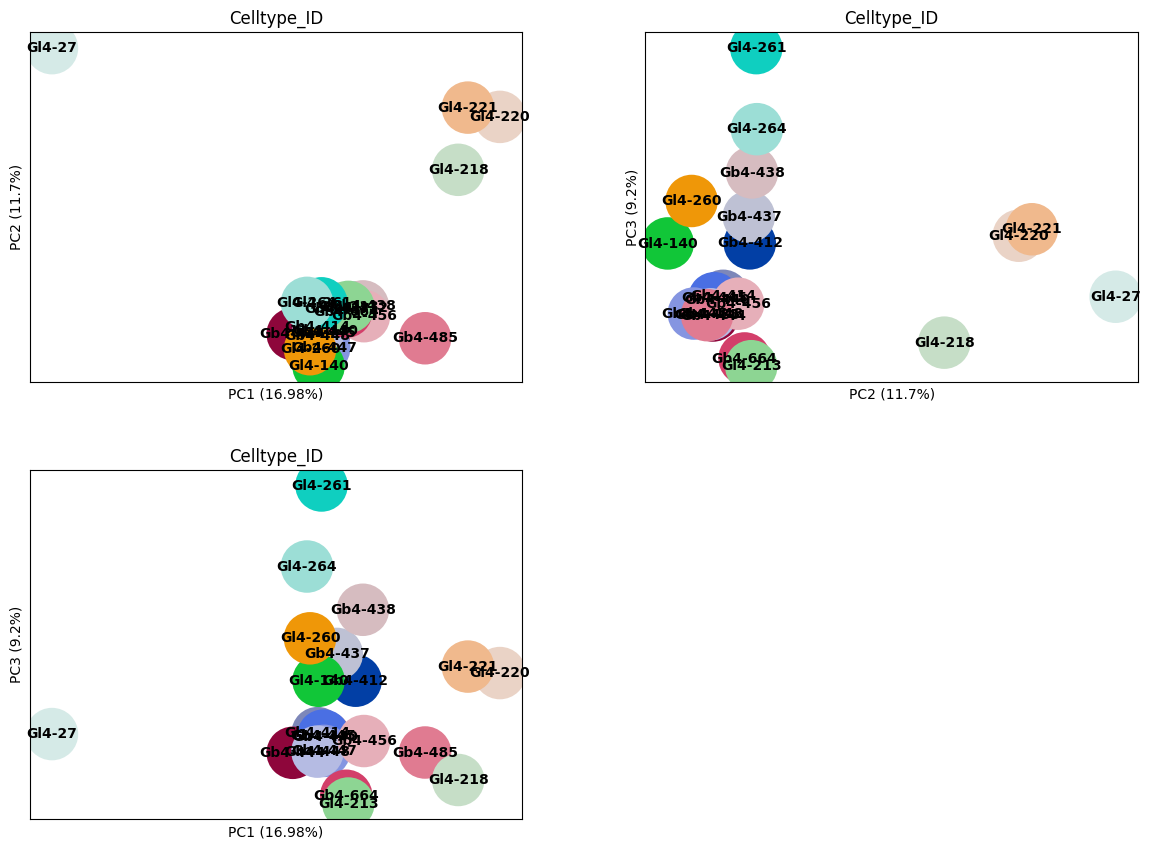

In [ ]:
sc.pl.pca(
    adata,
    color='Celltype_ID',
    legend_loc='on data',
    annotate_var_explained=True,
    components=['1,2', '2,3', '1,3'], ncols=2
)